# PCD_Assignment03
## Flower image segmentation and mathematical morphology from scratch

**Goal:** implement one segmentation method and several morphological operations,
then compare segmentation **without** and **with** morphological processing.

- **Input:** the supplied 242 × 226 flower photo, bundled as `images/flowers.png`.
- **Segmentation:** Otsu's global thresholding (manual histogram and threshold search).
- **Morphology:** binary erosion, dilation, opening, closing, morphological gradient, and inner boundary.
- **Comparison:** original color photo, grayscale input, binary masks, foreground coverage, and pixels added or removed by morphology.

All image-processing algorithms and mask statistics use Python lists, loops, and
the standard library. **No OpenCV, scikit-image, NumPy image operations, or library
thresholding/morphology functions are used.** Matplotlib only renders figures;
Pillow only decodes the source image and prepares the original color display.
Grayscale conversion is calculated manually.

Run all cells from top to bottom. The supplied photo is included in the repository;
no download is required. It has **no annotated ground-truth mask**, so the flower
comparison does not report accuracy, IoU, or Dice. An optional synthetic mode is
retained for checking those evaluation formulas separately.


In [1]:
from pathlib import Path
import random
import matplotlib.pyplot as plt

plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
SE = [[1, 1, 1], [1, 1, 1], [1, 1, 1]]


## 1. The supplied flower photograph

The default input is `images/flowers.png`, extracted without changing its bytes
from the supplied `Flower.zip` (original filename:
`Screenshot 2023-09-09 201719.png`). The image is used at its original 242 × 226
resolution; no artificial noise or resizing is applied.

The loader computes grayscale manually using
$Y = 0.299R + 0.587G + 0.114B$. Alpha is composited on white when present.
The original color photo and calculated grayscale image are displayed together.

**What is segmented?** Grayscale Otsu separates bright and dark intensity regions,
not semantic flower/background classes. Pale petals and pale wrapping may be
selected together, while dark petals, leaves, and flower centers may be excluded.
Morphology cannot resolve this semantic ambiguity.

Change `INPUT_IMAGE` to another local image path to experiment. Set it to `None`
only for the optional synthetic scene with known ground truth. That mode generates
geometric objects with fixed-seed Gaussian and salt/pepper noise and enables
reference-based accuracy metrics; its results do not describe this photo.


Input: 242 x 226; ground truth available: False
Source: images/flowers.png


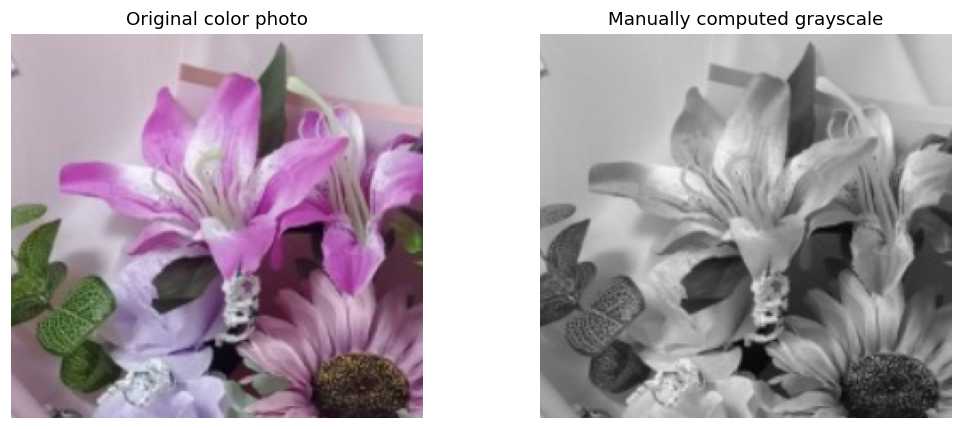

In [ ]:
def shape(image):
    """Validate a nonempty rectangular 2-D list and return (height, width)."""
    if not image or not image[0]:
        raise ValueError('Image must be nonempty.')
    width = len(image[0])
    if any(len(row) != width for row in image):
        raise ValueError('Image rows must have equal lengths.')
    return len(image), width


def synthetic_scene(height=128, width=176, seed=23):
    rng = random.Random(seed)
    truth = [[0] * width for _ in range(height)]
    for y in range(height):
        for x in range(width):
            disk = (x - 44) ** 2 + (y - 43) ** 2 <= 23 ** 2
            rectangle = 93 <= x <= 145 and 22 <= y <= 64
            ellipse = ((x - 93) / 32) ** 2 + ((y - 97) / 16) ** 2 <= 1
            truth[y][x] = int(disk or rectangle or ellipse)
    image = []
    for y in range(height):
        row = []
        for x in range(width):
            base = 185 if truth[y][x] else 45
            illumination = 12 * x / (width - 1)
            value = round(base + illumination + rng.gauss(0, 13))
            row.append(max(0, min(255, value)))
        image.append(row)
    for y in range(height):
        for x in range(width):
            if rng.random() < 0.045:
                image[y][x] = 255 if rng.random() < 0.5 else 0
    return image, truth


def read_grayscale(path):
    from PIL import Image
    with Image.open(path) as source:
        rgba = source.convert('RGBA')
        width, height = rgba.size
        pixels = [rgba.getpixel((x, y)) for y in range(height) for x in range(width)]
    result = []
    for y in range(height):
        row = []
        for x in range(width):
            r, g, b, alpha = pixels[y * width + x]
            a = alpha / 255
            r, g, b = (a * channel + (1 - a) * 255 for channel in (r, g, b))
            row.append(round(0.299 * r + 0.587 * g + 0.114 * b))
        result.append(row)
    return result


INPUT_IMAGE = 'images/flowers.png'
if INPUT_IMAGE is None:
    image, ground_truth = synthetic_scene()
else:
    image = read_grayscale(Path(INPUT_IMAGE))
    ground_truth = None
height, width = shape(image)
print(f'Input: {width} x {height}; ground truth available: {ground_truth is not None}')
print('Source:', INPUT_IMAGE if INPUT_IMAGE is not None else 'Synthetic scene (seed 23)')
fig, axes = plt.subplots(1, 2, figsize=(10, 4), squeeze=False)
if ground_truth is not None:
    axes[0][0].imshow(image, cmap='gray', vmin=0, vmax=255)
    axes[0][0].set_title('Synthetic grayscale input')
    axes[0][1].imshow(ground_truth, cmap='gray', vmin=0, vmax=1)
    axes[0][1].set_title('Clean ground truth')
else:
    from PIL import Image
    with Image.open(INPUT_IMAGE) as original:
        axes[0][0].imshow(original.convert('RGB'))
    axes[0][0].set_title('Original color photo')
    axes[0][1].imshow(image, cmap='gray', vmin=0, vmax=255)
    axes[0][1].set_title('Manually computed grayscale')
for ax in axes[0]:
    ax.axis('off')
plt.tight_layout()
plt.show()

## 2. Otsu segmentation from scratch

Otsu selects a threshold separating dark and bright pixels by maximizing the between-class variance:

$$\sigma_B^2(t) = w_0(t)w_1(t)[\mu_0(t)-\mu_1(t)]^2.$$

The classes are $[0,t]$ and $[t+1,255]$. We build the 256-bin histogram manually and scan all thresholds using cumulative counts and sums. The threshold search is $O(HW + 256)$; it does not repeatedly scan the image.

**Conventions:** foreground is `pixel > threshold`; empty classes are skipped; ties choose the smallest threshold. For a constant image, use its sole intensity as the threshold, yielding an empty foreground mask. This is a defined fallback, not evidence of two separable classes. Global thresholding assumes foreground and background differ in intensity; it is less reliable under strong uneven lighting.


Otsu threshold: 129; foreground convention: intensity > 129


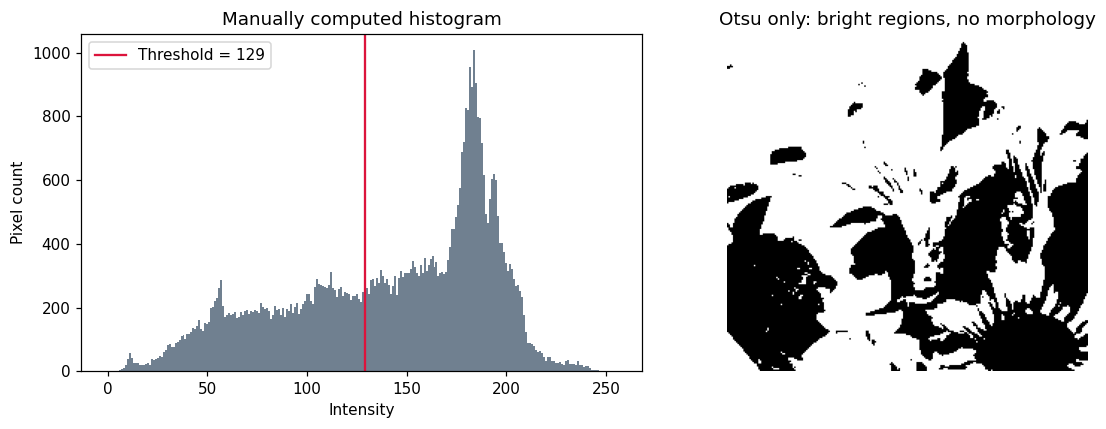

In [3]:
def histogram_256(image):
    shape(image)
    histogram = [0] * 256
    for row in image:
        for value in row:
            if not isinstance(value, int) or not 0 <= value <= 255:
                raise ValueError('Grayscale values must be integers in [0, 255].')
            histogram[value] += 1
    return histogram


def otsu_threshold(image):
    histogram = histogram_256(image)
    count = sum(histogram)
    total_sum = sum(level * frequency for level, frequency in enumerate(histogram))
    occupied = [level for level in range(256) if histogram[level]]
    if len(occupied) == 1:
        return occupied[0]
    background_count = 0
    background_sum = 0
    best_score = -1.0
    best_threshold = 0
    for threshold in range(256):
        background_count += histogram[threshold]
        background_sum += threshold * histogram[threshold]
        foreground_count = count - background_count
        if background_count == 0 or foreground_count == 0:
            continue
        mean_background = background_sum / background_count
        mean_foreground = (total_sum - background_sum) / foreground_count
        score = ((background_count / count) * (foreground_count / count)
                 * (mean_background - mean_foreground) ** 2)
        if score > best_score:
            best_score = score
            best_threshold = threshold
    return best_threshold


def threshold_mask(image, threshold):
    return [[int(value > threshold) for value in row] for row in image]


threshold = otsu_threshold(image)
raw_mask = threshold_mask(image, threshold)
histogram = histogram_256(image)
print(f'Otsu threshold: {threshold}; foreground convention: intensity > {threshold}')
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(range(256), histogram, width=1, color='slategray')
axes[0].axvline(threshold, color='crimson', label=f'Threshold = {threshold}')
axes[0].set(xlabel='Intensity', ylabel='Pixel count', title='Manually computed histogram')
axes[0].legend()
axes[1].imshow(raw_mask, cmap='gray', vmin=0, vmax=1)
axes[1].set_title('Otsu only: bright regions, no morphology')
axes[1].axis('off')
plt.tight_layout()
plt.show()


## 3. Binary morphological operations from scratch

White (`1`) is foreground. A centered **3 × 3 square** is the default structuring element $B$. All operations return new lists and leave the input unchanged.

| Operation | Definition | Typical effect |
|---|---|---|
| Erosion | $A \ominus B$ | Keeps a pixel only if every active neighbor is foreground; shrinks objects |
| Dilation | $A \oplus B$ | Keeps a pixel if any reflected active neighbor is foreground; expands objects |
| Opening | $(A \ominus B) \oplus B$ | Removes small foreground specks and thin protrusions |
| Closing | $(A \oplus B) \ominus B$ | Fills small holes and narrow gaps |
| Gradient | $(A \oplus B) - (A \ominus B)$ | Shows a band around object boundaries |
| Inner boundary | $A - (A \ominus B)$ | Shows boundary pixels inside the foreground |

**Border rule:** pixels outside the image are always background (zero padding), at every stage. Objects touching the image edge can therefore shrink during erosion or closing. This matters for the flower photo, whose bright regions reach the frame. The optional synthetic objects are away from the frame. Odd-sized rectangular footprints are supported; zero entries are ignored. Dilation explicitly reflects offsets, so asymmetric footprints also have a defined meaning. With $K$ active footprint cells, erosion and dilation each cost $O(HWK)$.


In [ ]:
def footprint_offsets(element):
    eh, ew = shape(element)
    if eh % 2 == 0 or ew % 2 == 0:
        raise ValueError('Structuring element dimensions must be odd.')
    if any(value not in (0, 1) for row in element for value in row):
        raise ValueError('Structuring element must contain only 0 or 1.')
    offsets = [(y - eh // 2, x - ew // 2)
               for y in range(eh) for x in range(ew) if element[y][x]]
    if not offsets:
        raise ValueError('Structuring element must have an active cell.')
    return offsets


def validate_binary(mask):
    h, w = shape(mask)
    if any(value not in (0, 1) for row in mask for value in row):
        raise ValueError('Mask must contain only 0 or 1.')
    return h, w


def erosion(mask, element=SE):
    h, w = validate_binary(mask)
    offsets = footprint_offsets(element)
    result = [[0] * w for _ in range(h)]
    for y in range(h):
        for x in range(w):
            keep = True
            for dy, dx in offsets:
                ny, nx = y + dy, x + dx
                if not (0 <= ny < h and 0 <= nx < w) or mask[ny][nx] == 0:
                    keep = False
                    break
            result[y][x] = int(keep)
    return result


def dilation(mask, element=SE):
    h, w = validate_binary(mask)
    offsets = footprint_offsets(element)
    result = [[0] * w for _ in range(h)]
    for y in range(h):
        for x in range(w):
            for dy, dx in offsets:
                ny, nx = y - dy, x - dx  
                if 0 <= ny < h and 0 <= nx < w and mask[ny][nx] == 1:
                    result[y][x] = 1
                    break
    return result


def opening(mask, element=SE):
    return dilation(erosion(mask, element), element)


def closing(mask, element=SE):
    return erosion(dilation(mask, element), element)


def mask_difference(left, right):
    if validate_binary(left) != validate_binary(right):
        raise ValueError('Masks must have matching dimensions.')
    return [[int(a == 1 and b == 0) for a, b in zip(row_a, row_b)]
            for row_a, row_b in zip(left, right)]


def morphological_gradient(mask, element=SE):
    return mask_difference(dilation(mask, element), erosion(mask, element))


def inner_boundary(mask, element=SE):
    return mask_difference(mask, erosion(mask, element))


## 4. Check the algorithms on hand-computable examples

These assertions check actual pixel results, threshold conventions, the border rule, and opening/closing behavior. They do not rely on a library implementation as an oracle. If an implementation breaks, running this cell should fail.


In [ ]:
def run_algorithm_checks():
    assert histogram_256([[0, 0, 200, 200]])[0] == 2
    assert otsu_threshold([[0, 0, 200, 200]]) == 0
    assert threshold_mask([[0, 0, 200, 200]], 0) == [[0, 0, 1, 1]]
    assert otsu_threshold([[75, 75]]) == 75
    assert threshold_mask([[75, 75]], 75) == [[0, 0]]
    single = [[int(y == 3 and x == 3) for x in range(7)] for y in range(7)]
    block = [[int(2 <= y <= 4 and 2 <= x <= 4) for x in range(7)] for y in range(7)]
    assert dilation(single) == block
    assert erosion(block) == single
    assert sum(map(sum, erosion([[1] * 3 for _ in range(3)]))) == 1
    assert opening(single) == [[0] * 7 for _ in range(7)]
    assert opening(block) == block
    assert opening(opening(block)) == opening(block)
    with_hole = [row[:] for row in block]
    with_hole[3][3] = 0
    assert closing(with_hole) == block
    assert sum(map(sum, inner_boundary(block))) == 8
    assert dilation([[0, 1, 0, 0]], [[0, 0, 1]]) == [[0, 0, 1, 0]]
    unchanged = [row[:] for row in block]
    erosion(block)
    dilation(block)
    assert block == unchanged
    for invalid in ([], [[0, 1], [1]]):
        try:
            erosion(invalid)
        except ValueError:
            pass
        else:
            raise AssertionError('Invalid mask was accepted.')
    print('All 17 algorithm checks passed (15 assertions + 2 rejected invalid inputs).')


run_algorithm_checks()


All 17 algorithm checks passed (15 assertions + 2 rejected invalid inputs).


## 5. Segment first, then apply morphology

Every treatment starts from the **same Otsu mask**, threshold, input, and 3 × 3
footprint. This isolates the effect of postprocessing. We compare erosion and
dilation separately, opening and closing separately, and both composition orders.
The primary demonstration is **opening → closing**: suppress small white regions,
then fill small dark gaps. Without annotations, small regions cannot automatically
be called noise, and filling a gap cannot automatically be called a correction.
The pipeline is fixed rather than selected to maximize any reference score.

Gradient and inner boundary are displayed separately because they are edge maps,
not complete region segmentations. White means the brighter intensity class.


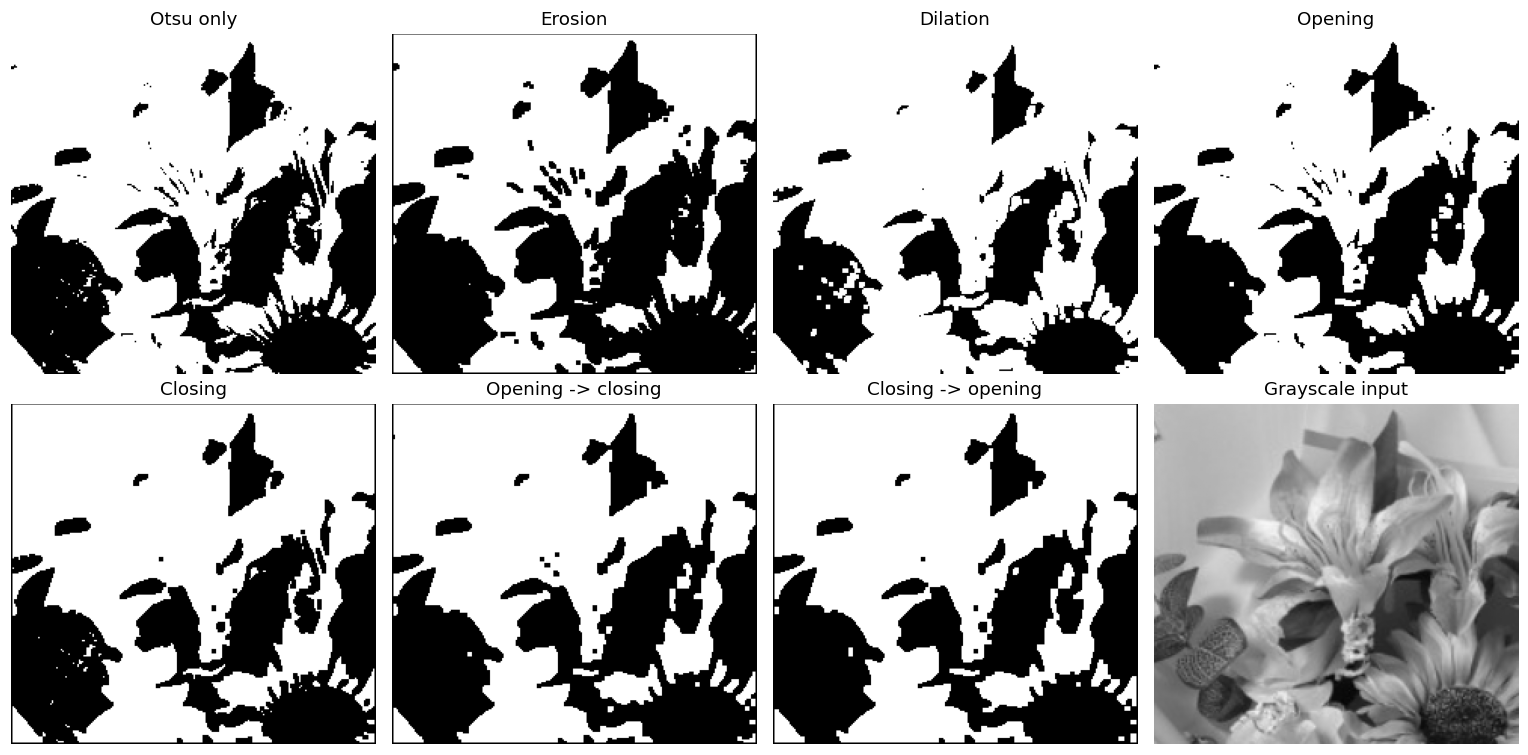

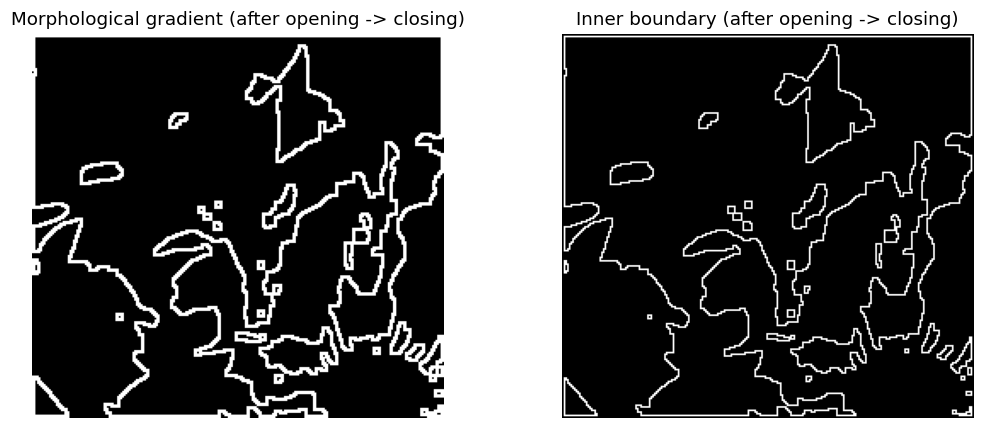

In [6]:
opened = opening(raw_mask)
closed = closing(raw_mask)
processed_mask = closing(opened)
variants = {
    'Otsu only': raw_mask,
    'Erosion': erosion(raw_mask),
    'Dilation': dilation(raw_mask),
    'Opening': opened,
    'Closing': closed,
    'Opening -> closing': processed_mask,
    'Closing -> opening': opening(closed),
}
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, (label, mask) in zip(axes.flat, variants.items()):
    ax.imshow(mask, cmap='gray', vmin=0, vmax=1)
    ax.set_title(label)
    ax.axis('off')
axes.flat[-1].imshow(image, cmap='gray', vmin=0, vmax=255)
axes.flat[-1].set_title('Grayscale input')
axes.flat[-1].axis('off')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, label, mask in zip(axes, ['Morphological gradient', 'Inner boundary'],
                            [morphological_gradient(processed_mask), inner_boundary(processed_mask)]):
    ax.imshow(mask, cmap='gray', vmin=0, vmax=1)
    ax.set_title(label + ' (after opening -> closing)')
    ax.axis('off')
plt.tight_layout()
plt.show()


## 6. Compare the masks without inventing accuracy scores

The flower photo has no reference mask, so the default run **does not calculate
segmentation accuracy, precision, recall, IoU, or Dice for this image**. Instead,
we compare foreground coverage and the numbers of pixels added or removed relative
to Otsu alone. Neither greater coverage nor fewer changed pixels establishes
better accuracy. The before/after mask panels provide the visual comparison.

### Optional reference-based evaluation

The functions below are retained and checked on a hand-computable example.
They are applied to the full image only if `INPUT_IMAGE = None` selects the
separate synthetic scene with a known ground-truth mask and a predicted mask:

| Metric | Formula |
|---|---|
| Intersection over Union (IoU) | `TP / (TP + FP + FN)` |
| Dice coefficient | `(2 * TP) / (2 * TP + FP + FN)` |

Here, `TP` means true-positive pixels, `FP` means false-positive pixels, and
`FN` means false-negative pixels. The formulas use plain text so they remain
readable in notebook viewers without mathematical typesetting support.

Precision measures how much predicted foreground is correct; recall measures how
much true foreground is recovered. Accuracy can hide errors when background
dominates. False positives are extra foreground pixels and false negatives are
missed foreground pixels, **relative to a reference mask**. Two empty masks have
IoU and Dice 1; precision or recall with a zero denominator is defined as 0.


In [ ]:
def segmentation_metrics(prediction, truth):
    if validate_binary(prediction) != validate_binary(truth):
        raise ValueError('Prediction and truth dimensions differ.')
    tp = fp = fn = tn = 0
    for pred_row, true_row in zip(prediction, truth):
        for pred, actual in zip(pred_row, true_row):
            if pred == 1 and actual == 1:
                tp += 1
            elif pred == 1:
                fp += 1
            elif actual == 1:
                fn += 1
            else:
                tn += 1
    union = tp + fp + fn
    dice_denominator = 2 * tp + fp + fn
    return {
        'IoU': tp / union if union else 1.0,
        'Dice': 2 * tp / dice_denominator if dice_denominator else 1.0,
        'Precision': tp / (tp + fp) if tp + fp else 0.0,
        'Recall': tp / (tp + fn) if tp + fn else 0.0,
        'Accuracy': (tp + tn) / (tp + tn + fp + fn),
        'FP': fp, 'FN': fn,
    }

example = segmentation_metrics([[1, 1], [0, 0]], [[1, 0], [1, 0]])
assert example['IoU'] == 1 / 3 and example['Dice'] == 0.5
assert example['FP'] == 1 and example['FN'] == 1

comparison = {}
if ground_truth is not None:
    comparison = {name: segmentation_metrics(mask, ground_truth) for name, mask in variants.items()}
    columns = ['IoU', 'Dice', 'Precision', 'Recall', 'Accuracy', 'FP', 'FN']
    print(f'{"Method":<23}' + ''.join(f'{column:>11}' for column in columns))
    print('-' * 100)
    for name, metrics in comparison.items():
        print(f'{name:<23}' + ''.join(
            f'{metrics[column]:>11d}' if column in ('FP', 'FN') else f'{metrics[column]:>11.4f}'
            for column in columns))
    names = list(comparison)
    fig, ax = plt.subplots(figsize=(11, 4))
    positions = list(range(len(names)))
    ax.bar([x - 0.18 for x in positions], [comparison[name]['IoU'] for name in names],
           width=0.36, label='IoU')
    ax.bar([x + 0.18 for x in positions], [comparison[name]['Dice'] for name in names],
           width=0.36, label='Dice')
    ax.set_xticks(positions, names, rotation=20, ha='right')
    ax.set(ylim=(0, 1.05), ylabel='Score (higher is better)', title='Segmentation quality by treatment')
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    print('No ground truth: inspect masks visually; accuracy scores cannot be inferred.')


No ground truth: inspect masks visually; accuracy scores cannot be inferred.


### Mask changes (also available without ground truth)

All treatments use the same threshold and footprint. Foreground percentage shows
how much of the image is white. Added pixels change from background to foreground;
removed pixels change from foreground to background. These counts quantify the
effect of morphology, not its correctness.

In [8]:
def mask_statistics(mask, baseline):
    h, w = validate_binary(mask)
    if (h, w) != validate_binary(baseline):
        raise ValueError('Mask and baseline dimensions differ.')
    foreground = added = removed = 0
    for y in range(h):
        for x in range(w):
            foreground += mask[y][x]
            added += int(mask[y][x] == 1 and baseline[y][x] == 0)
            removed += int(mask[y][x] == 0 and baseline[y][x] == 1)
    return {'foreground': foreground, 'coverage': 100 * foreground / (h * w),
            'added': added, 'removed': removed}


assert mask_statistics([[1, 0], [1, 0]], [[1, 1], [0, 0]]) == {
    'foreground': 2, 'coverage': 50.0, 'added': 1, 'removed': 1}
mask_changes = {name: mask_statistics(mask, raw_mask) for name, mask in variants.items()}
print(f'{"Method":<23}{"Foreground":>13}{"Coverage (%)":>15}{"Added":>12}{"Removed":>12}')
print('-' * 75)
for name, stats in mask_changes.items():
    print(f'{name:<23}{stats["foreground"]:>13d}{stats["coverage"]:>15.2f}'
          f'{stats["added"]:>12d}{stats["removed"]:>12d}')


Method                    Foreground   Coverage (%)       Added     Removed
---------------------------------------------------------------------------
Otsu only                      34518          63.11           0           0
Erosion                        29798          54.48           0        4720
Dilation                       38600          70.58        4082           0
Opening                        33834          61.86           0         684
Closing                        34575          63.22         699         642
Opening -> closing             33605          61.44         352        1265
Closing -> opening             34207          62.54         676         987


In [ ]:
def error_colors(prediction, truth):
    colors = []
    for pred_row, true_row in zip(prediction, truth):
        row = []
        for pred, actual in zip(pred_row, true_row):
            if pred and not actual:
                row.append([1.0, 0.2, 0.2])  
            elif actual and not pred:
                row.append([0.15, 0.55, 1.0])  
            elif actual:
                row.append([0.85, 0.85, 0.85])
            else:
                row.append([0.05, 0.05, 0.05])
        colors.append(row)
    return colors


if ground_truth is not None:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for ax, name, mask in zip(axes, ['Otsu only', 'Opening -> closing'], [raw_mask, processed_mask]):
        ax.imshow(error_colors(mask, ground_truth))
        ax.set_title(name)
        ax.axis('off')
    fig.suptitle('Red = false positive; blue = false negative; gray = correct foreground')
    plt.tight_layout()
    plt.show()


## 7. Results and discussion

The next cell derives its report from the current image. In the flower run it
reports mask changes only; optional synthetic accuracy results are not substituted
for measurements of the photo.


In [10]:
if comparison:
    before = comparison['Otsu only']
    after = comparison['Opening -> closing']
    best = max(comparison, key=lambda name: comparison[name]['IoU'])
    print(f'Otsu threshold: {threshold}')
    print(f'Opening -> closing changes IoU from {before["IoU"]:.4f} to {after["IoU"]:.4f} '
          f'({after["IoU"] - before["IoU"]:+.4f}).')
    print(f'Dice: {before["Dice"]:.4f} -> {after["Dice"]:.4f}.')
    print(f'False positives: {before["FP"]} -> {after["FP"]}; '
          f'false negatives: {before["FN"]} -> {after["FN"]}.')
    print(f'Highest IoU among the displayed treatments: {best}.')
    print('The primary pipeline improves IoU on this image.' if after['IoU'] > before['IoU']
          else 'The primary pipeline does not improve IoU on this image.')
else:
    print(f'Otsu threshold: {threshold}; foreground is intensity > {threshold}.')
    print(f'Otsu-only foreground coverage: {mask_changes["Otsu only"]["coverage"]:.2f}%.')
    stats = mask_changes['Opening -> closing']
    print(f'Opening -> closing: foreground coverage {stats["coverage"]:.2f}%; '
          f'{stats["added"]} pixels added and {stats["removed"]} removed.')
    print('Inspect the masks for removed small regions, filled gaps, lost detail, and merged regions.')
    print('These changes do not establish higher accuracy without a reference mask.')


Otsu threshold: 129; foreground is intensity > 129.
Otsu-only foreground coverage: 63.11%.
Opening -> closing: foreground coverage 61.44%; 352 pixels added and 1265 removed.
Inspect the masks for removed small regions, filled gaps, lost detail, and merged regions.
These changes do not establish higher accuracy without a reference mask.


### Interpretation and limitations

- **Without morphology:** Otsu assigns the brighter grayscale class to foreground.
  It cannot distinguish a bright petal from similarly bright wrapping or background.
- **Erosion and dilation:** erosion shrinks white regions and may remove thin petal
  features; dilation expands white regions and may join nearby regions. Their
  changed coverage and added/removed pixels are listed above.
- **Opening and closing:** opening suppresses small white regions or protrusions;
  closing fills small black gaps. Both compositions are shown because order matters.
  A changed mask is not necessarily a more accurate flower mask.
- **Frame effects:** zero padding treats the outside of the image as black at every
  stage. Erosion and closing can remove white pixels along the frame; those changes
  must not all be interpreted as noise removal.
- **Image-specific limitation:** purple/pink petals, dark leaves and centers, and
  pale wrapping have overlapping grayscale values. Morphology adjusts local shape
  but does not recover a semantic flower/background distinction.
- **Evidence:** these tables quantify changes to this supplied photo. No annotated
  mask was provided, so an accuracy improvement cannot be established. The optional
  synthetic scene is a separate controlled validation, not evidence about this photo.

### Conclusion

This notebook implements Otsu thresholding and six morphological operations without
image-processing libraries. The supplied flower photo is compared before and after
morphological processing using identical initial segmentation masks, side-by-side
figures, foreground coverage, and added/removed pixel counts. These operations alter
spatial structure; their usefulness depends on which regions should be retained,
the footprint, and the image boundary convention.